In [2]:
#data manipulation
import pandas as pd
import numpy as np

#data visulization
import matplotlib.pyplot as plt
import seaborn as sns

#machine learning 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# evaluation metrics
from sklearn.metrics import(
  accuracy_score,
  precision_score,
  recall_score,
  f1_score,
  confusion_matrix,
  classification_report
)

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
df=pd.read_csv("C:/Users/Deepak Kumar/Downloads/water_potability.csv")
print("dataset loaded successfully")

dataset loaded successfully


In [4]:
df.head


<bound method NDFrame.head of             ph    Hardness        Solids  Chloramines     Sulfate  \
0          NaN  204.890455  20791.318981     7.300212  368.516441   
1     3.716080  129.422921  18630.057858     6.635246         NaN   
2     8.099124  224.236259  19909.541732     9.275884         NaN   
3     8.316766  214.373394  22018.417441     8.059332  356.886136   
4     9.092223  181.101509  17978.986339     6.546600  310.135738   
...        ...         ...           ...          ...         ...   
3271  4.668102  193.681735  47580.991603     7.166639  359.948574   
3272  7.808856  193.553212  17329.802160     8.061362         NaN   
3273  9.419510  175.762646  33155.578218     7.350233         NaN   
3274  5.126763  230.603758  11983.869376     6.303357         NaN   
3275  7.874671  195.102299  17404.177061     7.509306         NaN   

      Conductivity  Organic_carbon  Trihalomethanes  Turbidity  Potability  
0       564.308654       10.379783        86.990970   2.963135  

In [5]:
df.tail

<bound method NDFrame.tail of             ph    Hardness        Solids  Chloramines     Sulfate  \
0          NaN  204.890455  20791.318981     7.300212  368.516441   
1     3.716080  129.422921  18630.057858     6.635246         NaN   
2     8.099124  224.236259  19909.541732     9.275884         NaN   
3     8.316766  214.373394  22018.417441     8.059332  356.886136   
4     9.092223  181.101509  17978.986339     6.546600  310.135738   
...        ...         ...           ...          ...         ...   
3271  4.668102  193.681735  47580.991603     7.166639  359.948574   
3272  7.808856  193.553212  17329.802160     8.061362         NaN   
3273  9.419510  175.762646  33155.578218     7.350233         NaN   
3274  5.126763  230.603758  11983.869376     6.303357         NaN   
3275  7.874671  195.102299  17404.177061     7.509306         NaN   

      Conductivity  Organic_carbon  Trihalomethanes  Turbidity  Potability  
0       564.308654       10.379783        86.990970   2.963135  

In [6]:
df.shape


(3276, 10)

In [7]:
df.columns


Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='str')

In [8]:
df.info


<bound method DataFrame.info of             ph    Hardness        Solids  Chloramines     Sulfate  \
0          NaN  204.890455  20791.318981     7.300212  368.516441   
1     3.716080  129.422921  18630.057858     6.635246         NaN   
2     8.099124  224.236259  19909.541732     9.275884         NaN   
3     8.316766  214.373394  22018.417441     8.059332  356.886136   
4     9.092223  181.101509  17978.986339     6.546600  310.135738   
...        ...         ...           ...          ...         ...   
3271  4.668102  193.681735  47580.991603     7.166639  359.948574   
3272  7.808856  193.553212  17329.802160     8.061362         NaN   
3273  9.419510  175.762646  33155.578218     7.350233         NaN   
3274  5.126763  230.603758  11983.869376     6.303357         NaN   
3275  7.874671  195.102299  17404.177061     7.509306         NaN   

      Conductivity  Organic_carbon  Trihalomethanes  Turbidity  Potability  
0       564.308654       10.379783        86.990970   2.963135

In [9]:
df.isnull().sum()




ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [10]:
missing_values=df.isnull().sum()
missing_percentage=(missing_values/len(df))*100
missing_data= pd.DataFrame({
    "Missing_values":missing_values,
    "Missing_Percentage":missing_percentage
})
missing_data.sort_values(
    by="Missing_Percentage",
    ascending=False
)
                    

,Missing_values,Missing_Percentage
Sulfate,781,23.840049
ph,491,14.987790
Trihalomethanes,162,4.945055
Hardness,0,0.000000
Chloramines,0,0.000000
Solids,0,0.000000
Conductivity,0,0.000000
Organic_carbon,0,0.000000
Turbidity,0,0.000000
Potability,0,0.000000


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [13]:
df["Potability"].value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

In [14]:
df["Potability"].value_counts(normalize=True) * 100

Potability
0    60.989011
1    39.010989
Name: proportion, dtype: float64

In [15]:
df.shape

(3276, 10)

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [17]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [18]:
df["Potability"].value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

In [19]:
df["Potability"].value_counts(normalize=True) * 100

Potability
0    60.989011
1    39.010989
Name: proportion, dtype: float64

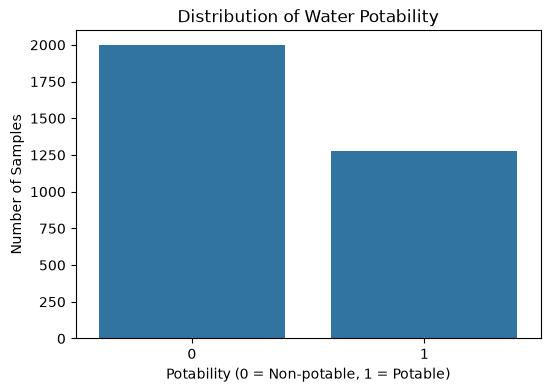

In [20]:
#visualize target distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Potability")

plt.title("Distribution of Water Potability")
plt.xlabel("Potability (0 = Non-potable, 1 = Potable)")
plt.ylabel("Number of Samples")

plt.show()

In [21]:
features = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

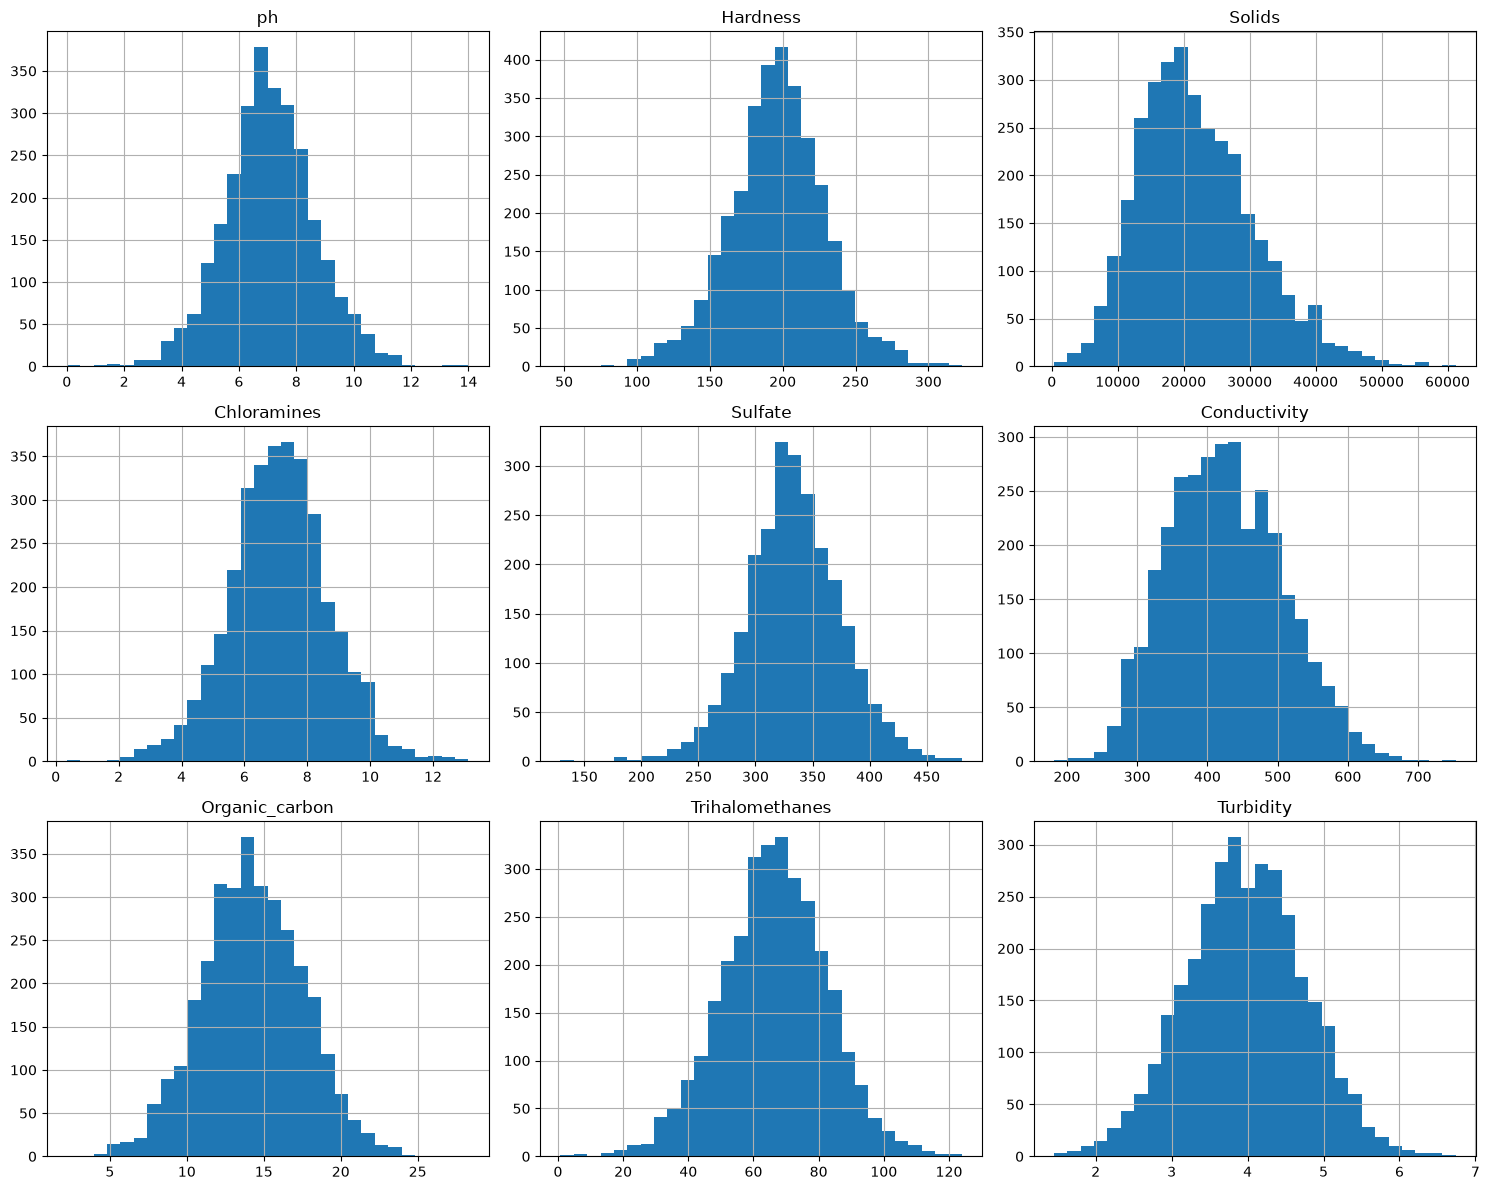

In [22]:
df[features].hist(figsize=(15, 12), bins=30)

plt.tight_layout()

plt.show()

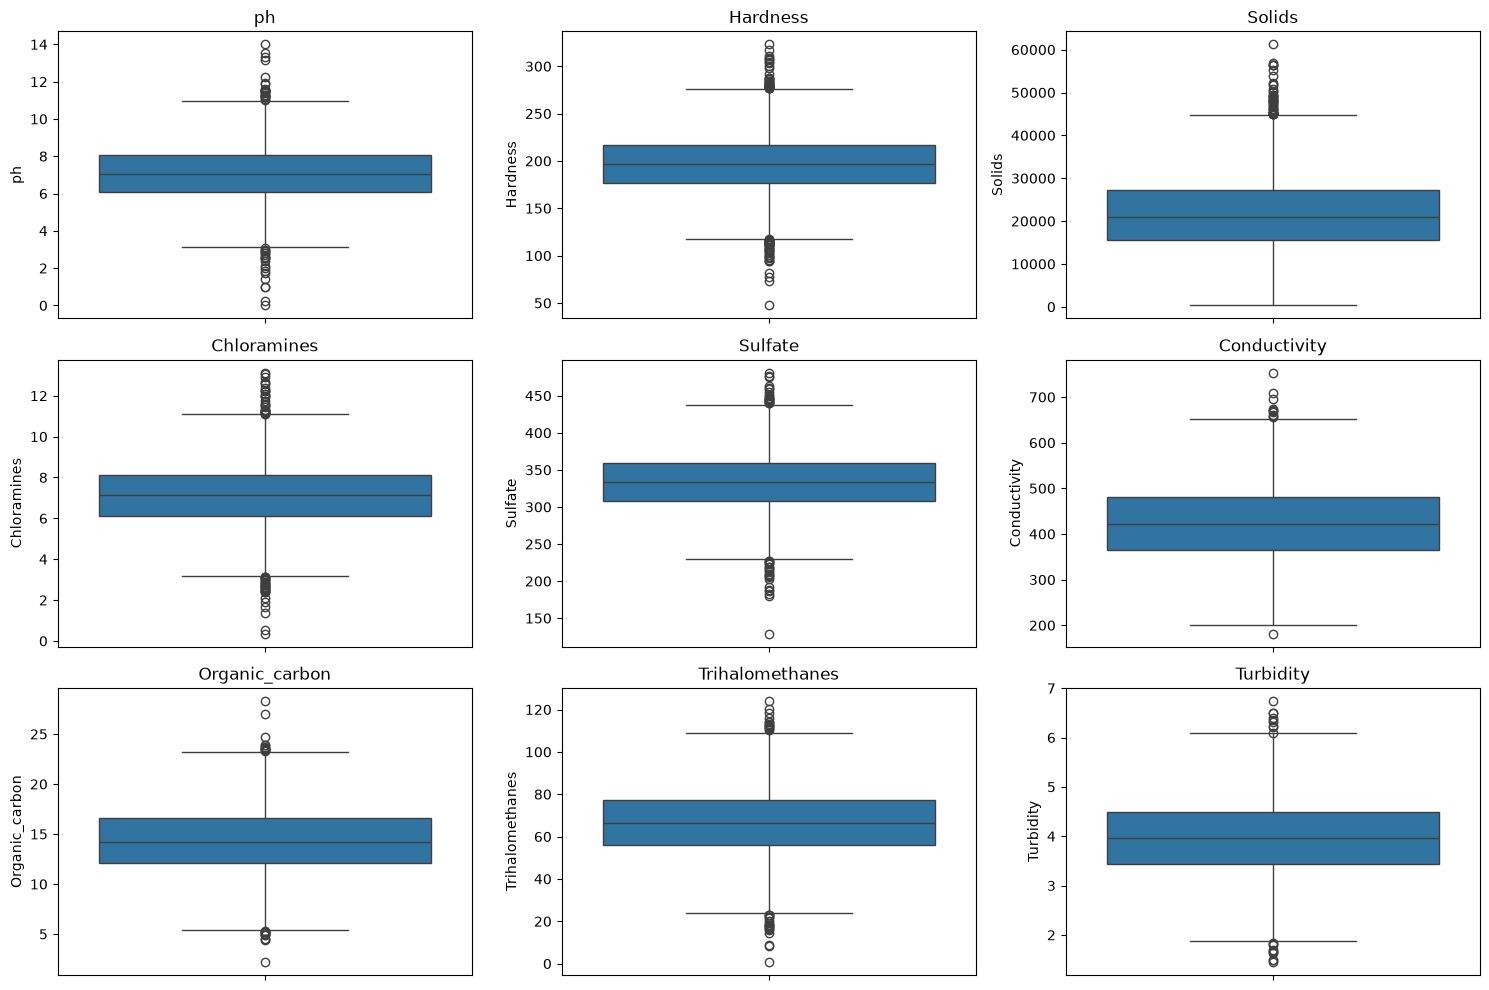

In [23]:
plt.figure(figsize=(15, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(3, 3, i)
    
    sns.boxplot(y=df[feature])
    
    plt.title(feature)

plt.tight_layout()

plt.show()

In [24]:
correlation = df.corr()

correlation

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
ph,1.000000,0.082096,-0.089288,-0.034350,0.018203,0.018614,0.043503,0.003354,-0.039057,-0.003556
Hardness,0.082096,1.000000,-0.046899,-0.030054,-0.106923,-0.023915,0.003610,-0.013013,-0.014449,-0.013837
Solids,-0.089288,-0.046899,1.000000,-0.070148,-0.171804,0.013831,0.010242,-0.009143,0.019546,0.033743
Chloramines,-0.034350,-0.030054,-0.070148,1.000000,0.027244,-0.020486,-0.012653,0.017084,0.002363,0.023779
Sulfate,0.018203,-0.106923,-0.171804,0.027244,1.000000,-0.016121,0.030831,-0.030274,-0.011187,-0.023577
Conductivity,0.018614,-0.023915,0.013831,-0.020486,-0.016121,1.000000,0.020966,0.001285,0.005798,-0.008128
Organic_carbon,0.043503,0.003610,0.010242,-0.012653,0.030831,0.020966,1.000000,-0.013274,-0.027308,-0.030001
Trihalomethanes,0.003354,-0.013013,-0.009143,0.017084,-0.030274,0.001285,-0.013274,1.000000,-0.022145,0.007130
Turbidity,-0.039057,-0.014449,0.019546,0.002363,-0.011187,0.005798,-0.027308,-0.022145,1.000000,0.001581
Potability,-0.003556,-0.013837,0.033743,0.023779,-0.023577,-0.008128,-0.030001,0.007130,0.001581,1.000000


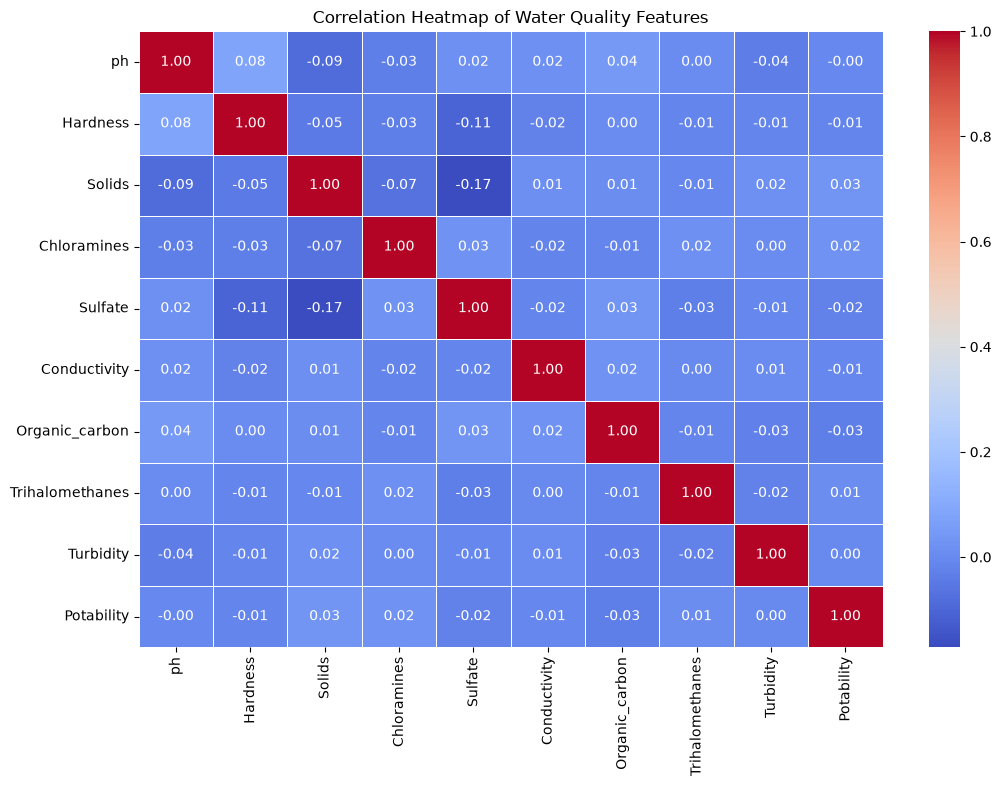

In [25]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Water Quality Features")

plt.show()

In [26]:
df.corr()["Potability"].sort_values(ascending=False)

Potability         1.000000
Solids             0.033743
Chloramines        0.023779
Trihalomethanes    0.007130
Turbidity          0.001581
ph                -0.003556
Conductivity      -0.008128
Hardness          -0.013837
Sulfate           -0.023577
Organic_carbon    -0.030001
Name: Potability, dtype: float64

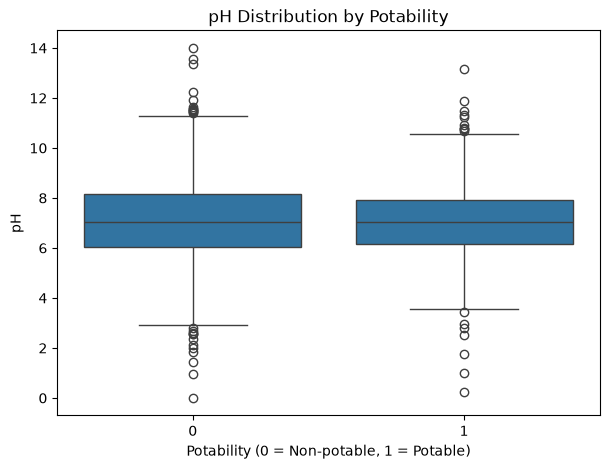

In [27]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="Potability", y="ph")

plt.title("pH Distribution by Potability")
plt.xlabel("Potability (0 = Non-potable, 1 = Potable)")
plt.ylabel("pH")

plt.show()

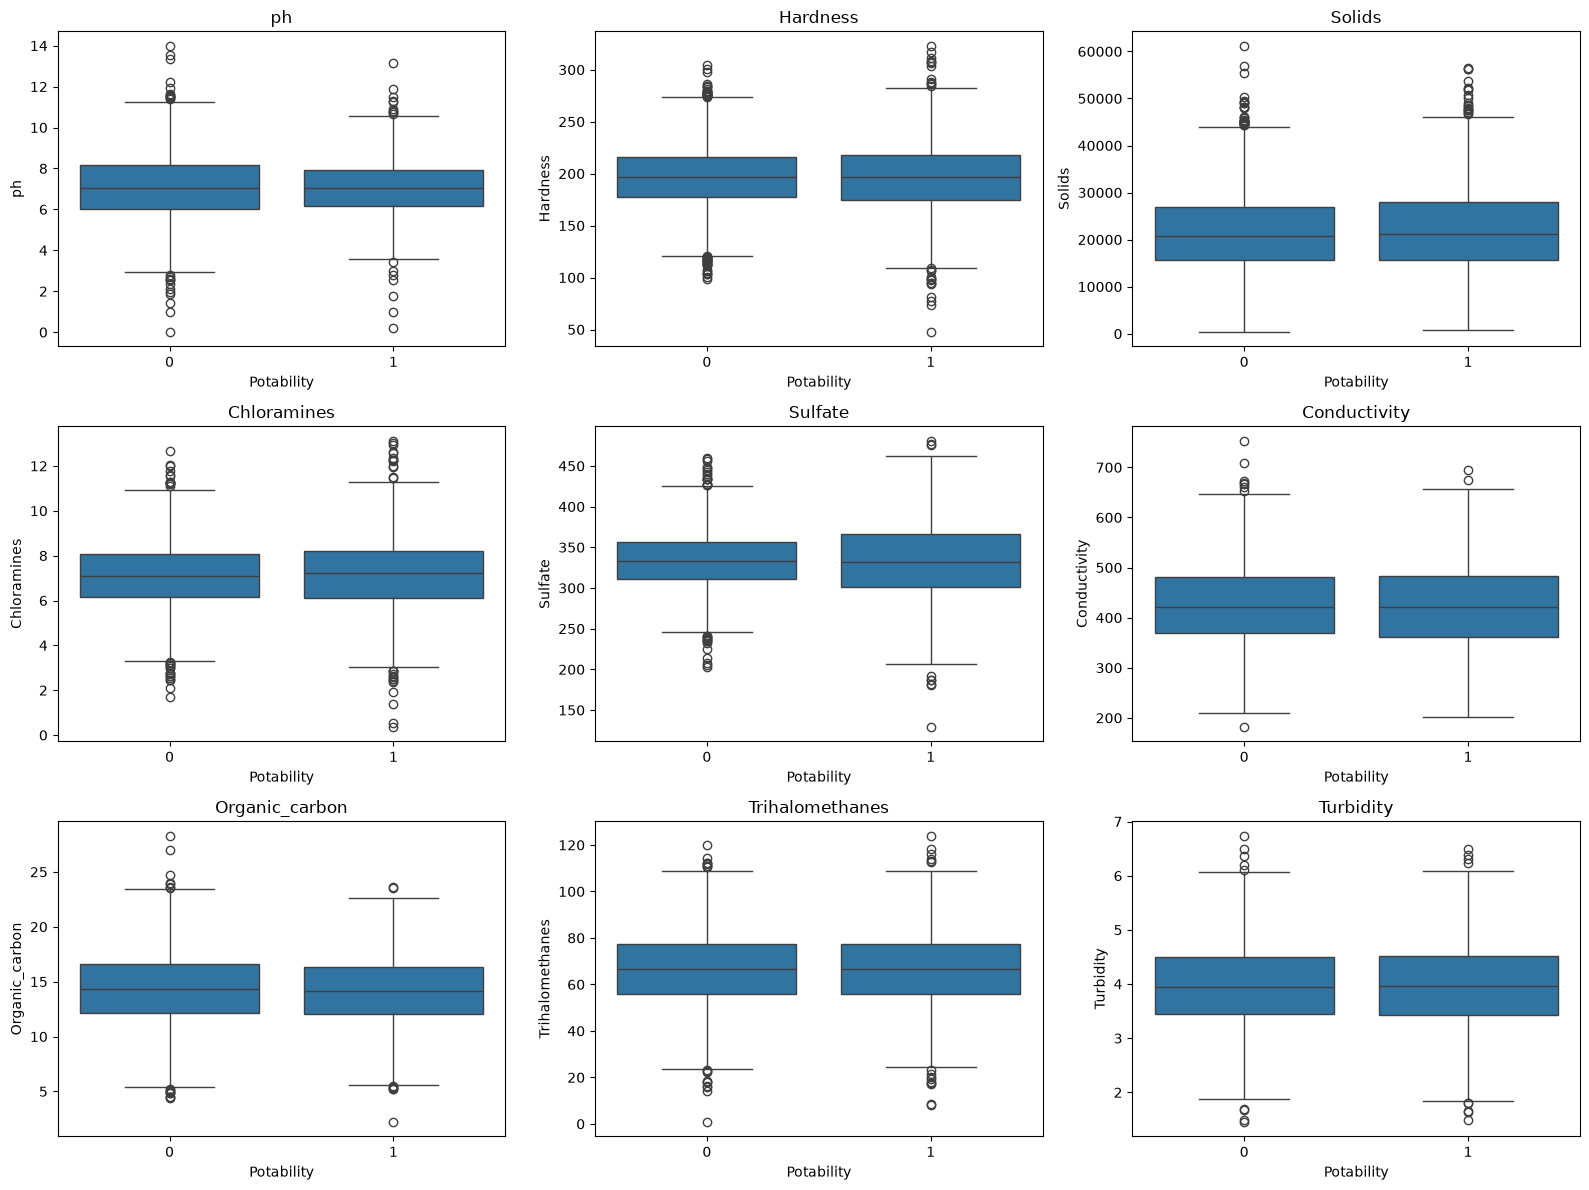

In [28]:
plt.figure(figsize=(16, 12))

for i, feature in enumerate(features, 1):
    plt.subplot(3, 3, i)
    
    sns.boxplot(data=df, x="Potability", y=feature)
    
    plt.title(feature)

plt.tight_layout()

plt.show()

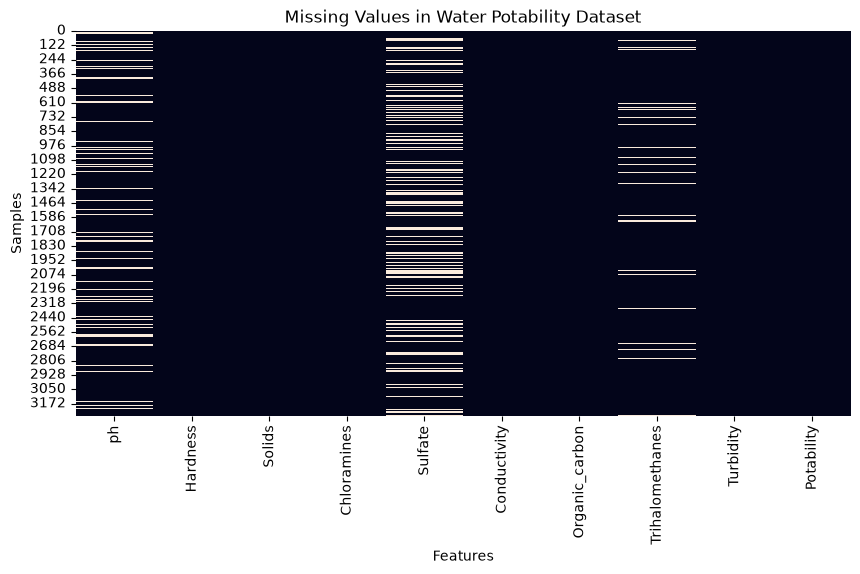

In [29]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Water Potability Dataset")

plt.xlabel("Features")
plt.ylabel("Samples")

plt.show()

In [30]:
missing = df.isnull().sum()

missing_percentage = (missing / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Values,Missing Percentage
Sulfate,781,23.840049
ph,491,14.987790
Trihalomethanes,162,4.945055
Hardness,0,0.000000
Chloramines,0,0.000000
Solids,0,0.000000
Conductivity,0,0.000000
Organic_carbon,0,0.000000
Turbidity,0,0.000000
Potability,0,0.000000


In [31]:
features = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

In [32]:
target = "Potability"

In [33]:
X = df[features]
y = df["Potability"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3276, 9)
Target shape: (3276,)


In [34]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

In [35]:
#perform train-test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test= train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [36]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2620, 9)
X_test: (656, 9)
y_train: (2620,)
y_test: (656,)


In [37]:
X_train_imputed=imputer.fit_transform(X_train)

In [38]:
X_test_imputed = imputer.transform(X_test)

In [39]:
print("Missing values in training data:", np.isnan(X_train_imputed).sum())
print("Missing values in testing data:", np.isnan(X_test_imputed).sum())

Missing values in training data: 0
Missing values in testing data: 0


In [40]:
#import scaler
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [41]:
X_train_scaled = scaler.fit_transform(X_train_imputed)

In [42]:
X_test_scaled=scaler.transform(X_test_imputed)

In [43]:
print("Training data mean:", np.mean(X_train_scaled, axis=0).round(2))

print("\nTraining data standard deviation:",
      np.std(X_train_scaled, axis=0).round(2))

Training data mean: [ 0. -0.  0.  0.  0.  0. -0. -0. -0.]

Training data standard deviation: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [44]:
comparison=pd.DataFrame({
    "Original pH":X_train_imputed[:,0],
     "Scaled pH": X_train_scaled[:, 0],

     "Original Solids": X_train_imputed[:, 2],
    "Scaled Solids": X_train_scaled[:, 2]
})
comparison.head()

,Original pH,Scaled pH,Original Solids,Scaled Solids
0,7.822492,0.505288,22308.821729,0.048040
1,6.037428,-0.709433,12988.791229,-1.016080
2,8.445219,0.929048,28966.569327,0.808192
3,6.745307,-0.227728,21871.838700,-0.001853
4,6.506488,-0.390242,17087.076902,-0.548156


In [45]:
print("Preprocessing completed successfully!")

print("\nTraining samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])

print("\nTraining features:", X_train_scaled.shape[1])
print("Testing features:", X_test_scaled.shape[1])

print("\nMissing values after preprocessing:",
      np.isnan(X_train_scaled).sum() + np.isnan(X_test_scaled).sum())

Preprocessing completed successfully!

Training samples: 2620
Testing samples: 656

Training features: 9
Testing features: 9

Missing values after preprocessing: 0


In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

print("Machine Learning algorithms imported successfully!")


Machine Learning algorithms imported successfully!


In [47]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    
    "SVM": SVC(
        kernel="rbf"
    )
}

In [48]:
LogisticRegression(max_iter=1000)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [49]:
DecisionTreeClassifier(random_state=42)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [50]:
RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [51]:
SVC(kernel="rbf")

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [52]:
#tree based algo don't require feature scaling
#scaled data for logisstic regression
#unscaled data for decision tree and random forest
#scaled data for svm
X_train_model = {
    "Logistic Regression": X_train_scaled,
    "Decision Tree": X_train_imputed,
    "Random Forest": X_train_imputed,
    "SVM": X_train_scaled
}

X_test_model = {
    "Logistic Regression": X_test_scaled,
    "Decision Tree": X_test_imputed,
    "Random Forest": X_test_imputed,
    "SVM": X_test_scaled
}

In [53]:
trained_models = {}

for name, model in models.items():
    
    print(f"Training {name}...")
    
    model.fit(X_train_model[name], y_train)
    
    trained_models[name] = model
    
print("\nAll models trained successfully!")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training SVM...

All models trained successfully!


In [54]:
#Generate Predictions 
predictions = {}

for name, model in trained_models.items():
    
    predictions[name] = model.predict(X_test_model[name])
    
    print(f"{name} predictions generated!")

Logistic Regression predictions generated!
Decision Tree predictions generated!
Random Forest predictions generated!
SVM predictions generated!


In [55]:
pd.DataFrame({
    "Actual": y_test.values,
    "Logistic Regression": predictions["Logistic Regression"],
    "Decision Tree": predictions["Decision Tree"],
    "Random Forest": predictions["Random Forest"],
    "SVM": predictions["SVM"]
}).head(10)

,Actual,Logistic Regression,Decision Tree,Random Forest,SVM
0,1,0,1,0,0
1,0,0,0,0,0
2,0,0,1,0,0
3,0,0,0,0,0
4,0,0,1,0,0
5,0,0,0,0,0
6,0,0,0,0,0
7,0,0,0,0,0
8,1,0,0,0,0
9,1,0,0,0,0


In [56]:
#save predictions in a Dataframe for further analysis
prediction_results = pd.DataFrame({
    "Actual": y_test.values
})

for name in predictions:
    prediction_results[name] = predictions[name]

prediction_results.head(10)

,Actual,Logistic Regression,Decision Tree,Random Forest,SVM
0,1,0,1,0,0
1,0,0,0,0,0
2,0,0,1,0,0
3,0,0,0,0,0
4,0,0,1,0,0
5,0,0,0,0,0
6,0,0,0,0,0
7,0,0,0,0,0
8,1,0,0,0,0
9,1,0,0,0,0


In [57]:
#calculate accuracy
from sklearn.metrics import accuracy_score

for name, y_pred in predictions.items():
    accuracy = accuracy_score(y_test, y_pred)
    
    print(f"{name}: {accuracy:.4f}")

Logistic Regression: 0.6098
Decision Tree: 0.5960
Random Forest: 0.6631
SVM: 0.6707


In [58]:
#calculate Precision,recall,f1-score
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

for name, y_pred in predictions.items():
    
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    print(f"\n{name}")
    print("-" * 35)
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")


Logistic Regression
-----------------------------------
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Decision Tree
-----------------------------------
Precision: 0.4813
Recall:    0.4531
F1-score:  0.4668

Random Forest
-----------------------------------
Precision: 0.6446
Recall:    0.3047
F1-score:  0.4138

SVM
-----------------------------------
Precision: 0.7041
Recall:    0.2695
F1-score:  0.3898


In [59]:
#model comparison table
results = []

for name, y_pred in predictions.items():
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.596037,0.481328,0.453125,0.466801
2,Random Forest,0.663110,0.644628,0.304688,0.413793
3,SVM,0.670732,0.704082,0.269531,0.389831
0,Logistic Regression,0.609756,0.000000,0.000000,0.000000


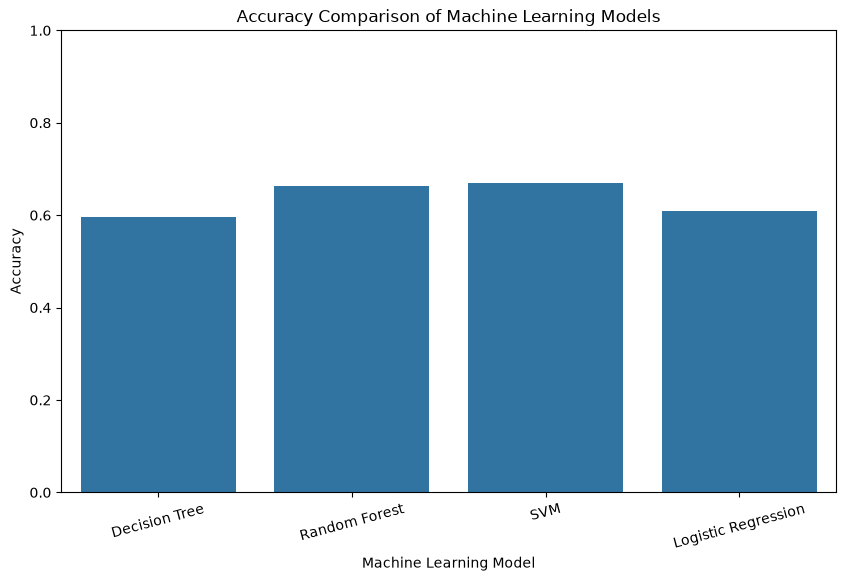

In [60]:
#visualize 
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

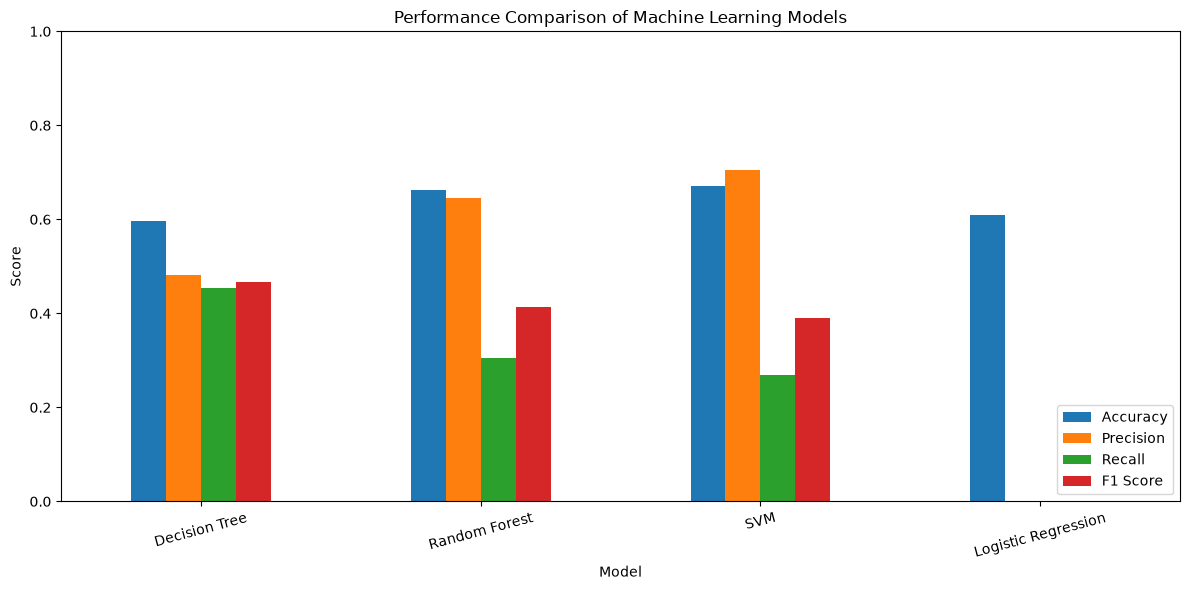

In [61]:
#compare evaluation matrics
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_plot = results_df.set_index("Model")[metrics_to_plot]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Machine Learning Models")

plt.ylabel("Score")
plt.xlabel("Model")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

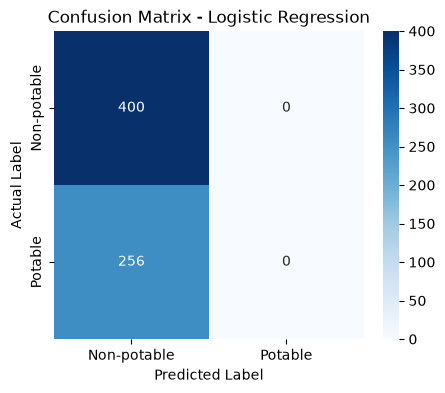

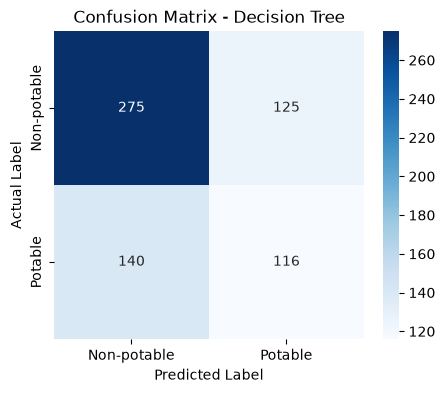

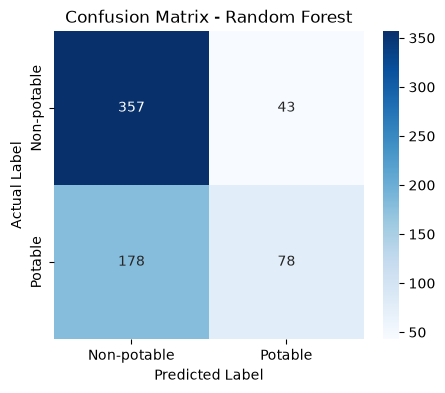

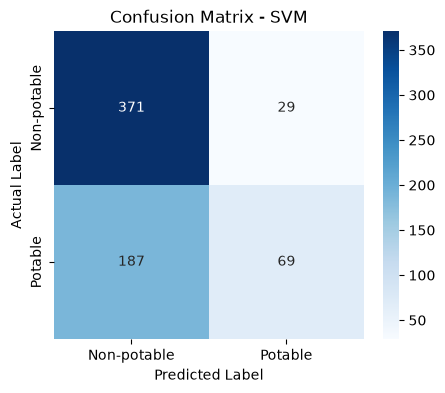

In [62]:
#confusion matrix
from sklearn.metrics import confusion_matrix

for name, y_pred in predictions.items():
    
    cm = confusion_matrix(y_test, y_pred)
    
    plt.figure(figsize=(5, 4))
    
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-potable", "Potable"],
        yticklabels=["Non-potable", "Potable"]
    )
    
    plt.title(f"Confusion Matrix - {name}")
    
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    
    plt.show()

In [63]:
#classification Reports 
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():
    
    print("=" * 60)
    print(name)
    print("=" * 60)
    
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Non-potable", "Potable"],
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

 Non-potable       0.61      1.00      0.76       400
     Potable       0.00      0.00      0.00       256

    accuracy                           0.61       656
   macro avg       0.30      0.50      0.38       656
weighted avg       0.37      0.61      0.46       656

Decision Tree
              precision    recall  f1-score   support

 Non-potable       0.66      0.69      0.67       400
     Potable       0.48      0.45      0.47       256

    accuracy                           0.60       656
   macro avg       0.57      0.57      0.57       656
weighted avg       0.59      0.60      0.59       656

Random Forest
              precision    recall  f1-score   support

 Non-potable       0.67      0.89      0.76       400
     Potable       0.64      0.30      0.41       256

    accuracy                           0.66       656
   macro avg       0.66      0.60      0.59       656
weighted avg       0.66   

In [64]:
#identify the best model
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model based on F1-score:", best_model_name)

print("\nPerformance:")
print(results_df.iloc[0])

Best model based on F1-score: Decision Tree

Performance:
Model        Decision Tree
Accuracy          0.596037
Precision         0.481328
Recall            0.453125
F1 Score          0.466801
Name: 1, dtype: object


In [65]:
#save experimental results
results_df.to_csv(
    "water_potability_model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [66]:
#where csv file saved
import os

print(os.getcwd())

C:\Users\Deepak Kumar


In [67]:
import os
print(os.path.abspath("water_potability_model_comparison.csv"))

C:\Users\Deepak Kumar\water_potability_model_comparison.csv


In [68]:
#prepare the tuning environment
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [69]:
#tune decision tree
dt_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42))
])

In [70]:
#hyperparameter combinations 
dt_param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 7, 10, 15, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10]
}

In [71]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [72]:
#perform tuning
dt_grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

dt_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 192 candidates, totalling 960 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more a

In [73]:
print("Best Decision Tree Parameters:")
print(dt_grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(dt_grid_search.best_score_)

Best Decision Tree Parameters:
{'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 20}

Best Cross-Validation F1 Score:
0.5049109883361689


In [ ]:
#tune random forest
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=42))
])

In [ ]:
#parameter grid
rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 10, 15, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

In [ ]:
#grid search
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

In [ ]:
print("Best Random Forest Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(rf_grid_search.best_score_)

In [ ]:
tuned_models = {
    "Tuned Decision Tree": dt_grid_search.best_estimator_,
    "Tuned Random Forest": rf_grid_search.best_estimator_
}

tuned_predictions = {}

for name, model in tuned_models.items():
    tuned_predictions[name] = model.predict(X_test)

In [ ]:
#comparison table
comparison = []

# Baseline models
for name, y_pred in predictions.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

# Tuned models
for name, y_pred in tuned_predictions.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

comparison_df

In [ ]:
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Baseline vs Tuned Model Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
#save stage 6 
comparison_df.to_csv(
    "water_potability_improved_model_comparison.csv",
    index=False
)

print("Improved model comparison saved succelly!")

In [82]:
import joblib

In [83]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['ph','Hardness','Solids',...,'Organic_carbon','Trihalomethanes', 'Turbidity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or o

In [84]:
#save the pipeline
joblib.dump(final_model, "water_potability_final_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [85]:
loaded_model = joblib.load("water_potability_final_model.pkl")

sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Sample predictions:", sample_prediction)
print("Actual values:", y_test.iloc[:5].values)

Sample predictions: [1 0 1 0 1]
Actual values: [1 0 0 0 0]


In [86]:
!pip install streamlit

In [87]:
#verify
import streamlit as st

print("Streamlit installed successfully!")
print("Version:", st.__version__)

Streamlit installed successfully!
Version: 1.58.0


In [89]:
import os
import shutil

# Your VS Code project folder
project_path = r"C:\Users\Deepak Kumar\Desktop\Water_Potability_Project"

# Copy dataset
shutil.copy(
    r"C:\Users\Deepak Kumar\Downloads\water_potability.csv",
    os.path.join(project_path, "dataset", "water_potability.csv")
)

# Copy notebook
shutil.copy(
    os.path.abspath("Water_Potability_Project.ipynb"),
    os.path.join(project_path, "notebooks", "Water_Potability_Project.ipynb")
)

# Copy model comparison CSV
shutil.copy(
    os.path.abspath("water_potability_model_comparison.csv"),
    os.path.join(project_path, "reports", "water_potability_model_comparison.csv")
)

# Copy improved model comparison CSV
shutil.copy(
    os.path.abspath("water_potability_improved_model_comparison.csv"),
    os.path.join(project_path, "reports", "water_potability_improved_model_comparison.csv")
)

print("Files copied successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Deepak Kumar\\Desktop\\Water_Potability_Project\\dataset\\water_potability.csv'

In [90]:
import os

project_path = r"C:\Users\Deepak Kumar\Desktop\Water_Potability_Project"

# Create all required folders automatically
folders = [
    "app",
    "model",
    "dataset",
    "reports",
    "notebooks"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("All project folders created successfully!")

All project folders created successfully!


In [91]:
import shutil
import os

dataset_source = r"C:\Users\Deepak Kumar\Downloads\water_potability.csv"

dataset_destination = os.path.join(
    project_path,
    "dataset",
    "water_potability.csv"
)

shutil.copy2(dataset_source, dataset_destination)

print("Dataset copied successfully!")

Dataset copied successfully!


In [92]:
print(os.path.exists(dataset_destination))

True
